# Logistic Regression as a Neural Network
(partly following deeplearning.ai lab)

- Initializing parameters
- Calculating the cost function and its gradient
- Using an optimization algorithm (gradient descent)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
%matplotlib inline

## General Architecture of the algorithm

Build a Logistic Regression, using a Neural Network mindset.

Mathematical expression of the algorithm:

For one example $x^{(i)}$:
$$z^{(i)} = w^T x^{(i)} + b \tag{1}$$
$$\hat{y}^{(i)} = a^{(i)} = sigmoid(z^{(i)})\tag{2}$$
$$L(a^{(i)}, y^{(i)}) = - y^{(i)} \log(a^{(i)}) - (1-y^{(i)}) \log(1-a^{(i)})\tag{3}$$

The cost is then computed by summing over all training examples:
$$J = \frac{1}{m} \sum_{i=1}^m L(a^{(i)}, y^{(i)})$$

In [2]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1. / (1. + np.exp(-z))

In [3]:
def initialize_with_zeros(dim):
    w = np.zeros((dim, 1))
    b = 0.0
    return w, b

In [4]:
def propagate(w, b, X, Y):
    m = X.shape[1]
    A = sigmoid(np.dot(w.T, X) + b)
    eps = 1e-15
    A_clipped = np.clip(A, eps, 1 - eps)
    cost = -(1. / m) * np.sum(Y * np.log(A_clipped) + (1 - Y) * np.log(1 - A_clipped))

    dw = (1. / m) * np.dot(X, (A - Y).T)
    db = (1. / m) * np.sum(A - Y)

    grads = {"dw": dw, "db": db}
    return grads, float(cost)

In [5]:
def predict(w, b, X, threshold=0.5):
    A = sigmoid(np.dot(w.T, X) + b)
    return (A > threshold).astype(int)

## Data Loading and Preprocessing

In [6]:
df = pd.read_csv("workshops/3/bioresponse.csv")
df.shape

(3751, 1777)

In [7]:
X = df.iloc[:, 1:].values
y = df.iloc[:, 0].values

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

train_set_x = X_train_raw.T
test_set_x = X_test_raw.T
train_set_y = y_train_raw.reshape(1, -1)
test_set_y = y_test_raw.reshape(1, -1)

print(f"train_set_x shape: {train_set_x.shape}, test_set_x shape: {test_set_x.shape}")

train_set_x shape: (1776, 2813), test_set_x shape: (1776, 938)


## 1. Classic Gradient Descent (GD)

In [8]:
def optimize(w, b, X, Y, num_iterations, learning_rate, print_cost=False):
    costs = []

    for i in range(num_iterations):
        grads, cost = propagate(w, b, X, Y)
        w = w - learning_rate * grads["dw"]
        b = b - learning_rate * grads["db"]

        if i % 10 == 0:
            costs.append(cost)
        if print_cost and i % 200 == 0:
            print(f"Cost after iteration {i}: {cost:.6f}")

    params = {"w": w, "b": b}
    return params, grads, costs

## 2. Stochastic Gradient Descent (SGD)

In [9]:
def optimize_sgd(w, b, X, Y, num_iterations, learning_rate, print_cost=False, seed=42):
    costs = []
    m = X.shape[1]
    np.random.seed(seed)

    for i in range(num_iterations):
        idx = np.random.randint(0, m)
        x_i = X[:, idx:idx + 1]
        y_i = Y[:, idx:idx + 1]

        grads, _ = propagate(w, b, x_i, y_i)
        w = w - learning_rate * grads["dw"]
        b = b - learning_rate * grads["db"]

        if i % 10 == 0:
            _, full_cost = propagate(w, b, X, Y)
            costs.append(full_cost)
        if print_cost and i % 200 == 0:
            _, full_cost = propagate(w, b, X, Y)
            print(f"SGD Cost after iteration {i}: {full_cost:.6f}")

    params = {"w": w, "b": b}
    return params, grads, costs

## 3. Adam Optimization

In [10]:
def optimize_adam(w, b, X, Y, num_iterations, learning_rate, beta1=0.9, beta2=0.999, epsilon=1e-8, print_cost=False):
    costs = []
    vdw = np.zeros_like(w)
    vdb = 0.0
    sdw = np.zeros_like(w)
    sdb = 0.0

    for i in range(num_iterations):
        t = i + 1
        grads, cost = propagate(w, b, X, Y)
        dw, db = grads["dw"], grads["db"]

        vdw = beta1 * vdw + (1 - beta1) * dw
        vdb = beta1 * vdb + (1 - beta1) * db
        sdw = beta2 * sdw + (1 - beta2) * (dw ** 2)
        sdb = beta2 * sdb + (1 - beta2) * (db ** 2)

        vdw_corr = vdw / (1 - beta1 ** t)
        vdb_corr = vdb / (1 - beta1 ** t)
        sdw_corr = sdw / (1 - beta2 ** t)
        sdb_corr = sdb / (1 - beta2 ** t)

        w = w - learning_rate * (vdw_corr / (np.sqrt(sdw_corr) + epsilon))
        b = b - learning_rate * (vdb_corr / (np.sqrt(sdb_corr) + epsilon))

        if i % 10 == 0:
            costs.append(cost)
        if print_cost and i % 200 == 0:
            print(f"Adam Cost after iteration {i}: {cost:.6f}")

    params = {"w": w, "b": b}
    return params, grads, costs

## Model Training and Optimizer Comparison (Parts 1-3)

In [11]:
def model(X_train, Y_train, X_test, Y_test, optimizer="gd", num_iterations=2000, learning_rate=0.01, print_cost=False):
    w, b = initialize_with_zeros(X_train.shape[0])

    if optimizer == "gd":
        parameters, grads, costs = optimize(w, b, X_train, Y_train, num_iterations, learning_rate, print_cost)
    elif optimizer == "sgd":
        parameters, grads, costs = optimize_sgd(w, b, X_train, Y_train, num_iterations, learning_rate, print_cost)
    elif optimizer == "adam":
        parameters, grads, costs = optimize_adam(w, b, X_train, Y_train, num_iterations, learning_rate,
                                                 print_cost=print_cost)
    else:
        raise ValueError("Unknown optimizer")

    w, b = parameters["w"], parameters["b"]
    Y_prediction_test = predict(w, b, X_test)
    Y_prediction_train = predict(w, b, X_train)

    train_acc = 100 - np.mean(np.abs(Y_prediction_train - Y_train)) * 100
    test_acc = 100 - np.mean(np.abs(Y_prediction_test - Y_test)) * 100

    return {
        "costs": costs,
        "Y_prediction_test": Y_prediction_test,
        "Y_prediction_train": Y_prediction_train,
        "w": w,
        "b": b,
        "train_acc": train_acc,
        "test_acc": test_acc,
        "learning_rate": learning_rate,
        "num_iterations": num_iterations
    }

In [12]:
results_optimizers = {
    "GD": model(train_set_x, train_set_y, test_set_x, test_set_y, optimizer="gd", num_iterations=2000,
                learning_rate=0.01),
    "SGD": model(train_set_x, train_set_y, test_set_x, test_set_y, optimizer="sgd", num_iterations=2000,
                 learning_rate=0.01),
    "Adam": model(train_set_x, train_set_y, test_set_x, test_set_y, optimizer="adam", num_iterations=2000,
                  learning_rate=0.01)
}

rows_comp = []
for name, res in results_optimizers.items():
    rows_comp.append({
        "Optimizer": name,
        "Learning Rate": res["learning_rate"],
        "Final Cost": round(res["costs"][-1], 4),
        "Train Accuracy (%)": round(res["train_acc"], 2),
        "Test Accuracy (%)": round(res["test_acc"], 2)
    })
comparison_df = pd.DataFrame(rows_comp)
comparison_df

,Optimizer,Learning Rate,Final Cost,Train Accuracy (%),Test Accuracy (%)
0,GD,0.01,0.4671,79.38,73.24
1,SGD,0.01,0.5083,77.78,71.64
2,Adam,0.01,0.1588,94.85,73.03


At the same learning rate (`lr = 0.01`) and 2000 iterations, Adam reaches the lowest cost and highest training accuracy, though it shows stronger overfitting on 1776 features without regularization compared to classic GD. Single-sample SGD has lower accuracy within 2000 steps since each iteration updates weights using only one random molecule.

## 4. Learning Curves Comparison (GD, SGD, Adam)

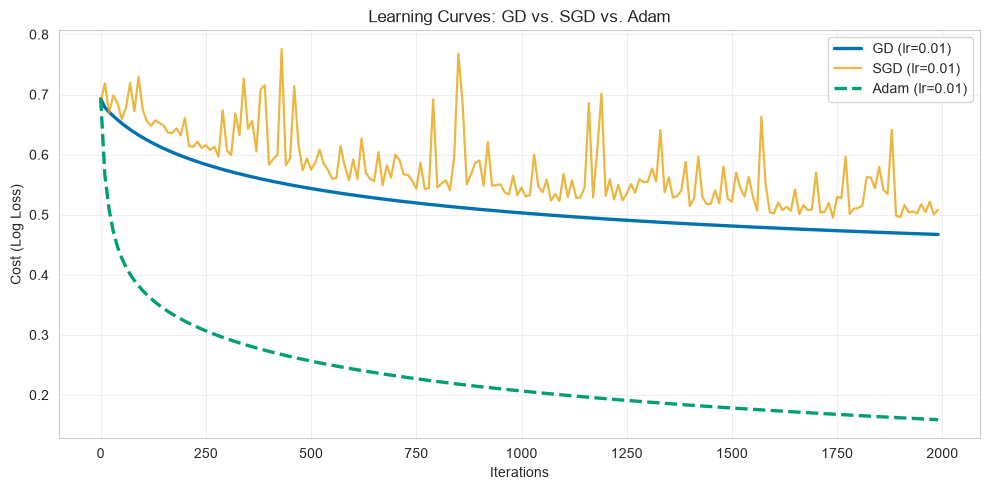

In [13]:
styles = {
    "GD": {"color": "#0072B2", "lw": 2.4, "alpha": 1.0, "ls": "-"},
    "SGD": {"color": "#E69F00", "lw": 1.6, "alpha": 0.75, "ls": "-"},
    "Adam": {"color": "#009E73", "lw": 2.4, "alpha": 1.0, "ls": "--"},
}

plt.figure(figsize=(10, 5))
for name, res in results_optimizers.items():
    iters = np.arange(len(res["costs"])) * 10
    s = styles[name]
    plt.plot(
        iters, res["costs"],
        color=s["color"],
        linewidth=s["lw"],
        alpha=s["alpha"],
        linestyle=s["ls"],
        label=f"{name} (lr={res['learning_rate']})"
    )

plt.title("Learning Curves: GD vs. SGD vs. Adam")
plt.xlabel("Iterations")
plt.ylabel("Cost (Log Loss)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Effect of Learning Rate on Convergence and Accuracy

In [14]:
learning_rates = [0.0001, 0.001, 0.01, 0.05, 0.1]

all_lr_results = {}
rows = []

for opt_name in ["GD", "SGD", "Adam"]:
    all_lr_results[opt_name] = {}
    for lr in learning_rates:
        res = model(
            train_set_x, train_set_y, test_set_x, test_set_y,
            optimizer=opt_name.lower(), num_iterations=2000, learning_rate=lr
        )
        all_lr_results[opt_name][lr] = res
        rows.append({
            "Optimizer": opt_name,
            "Learning Rate": lr,
            "Final Cost": round(res["costs"][-1], 4),
            "Train Accuracy (%)": round(res["train_acc"], 2),
            "Test Accuracy (%)": round(res["test_acc"], 2)
        })

lr_summary_df = pd.DataFrame(rows)
lr_summary_df

,Optimizer,Learning Rate,Final Cost,Train Accuracy (%),Test Accuracy (%)
0,GD,0.0001,0.6710,56.99,56.29
1,GD,0.0010,0.5959,72.20,69.30
2,GD,0.0100,0.4671,79.38,73.24
3,GD,0.0500,0.3999,82.51,75.37
4,GD,0.1000,0.3731,83.43,75.59
5,SGD,0.0001,0.6710,56.70,55.65
6,SGD,0.0010,0.6001,71.17,67.16
7,SGD,0.0100,0.5083,77.78,71.64
8,SGD,0.0500,1.2084,76.08,72.49
9,SGD,0.1000,1.9677,74.80,70.79


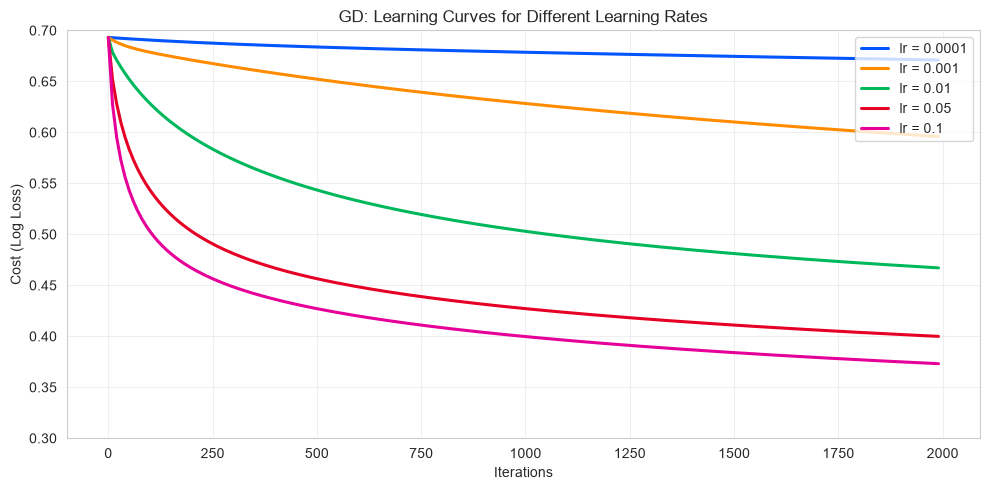

In [15]:
palette = ["#0055FF", "#FF8C00", "#00B85C", "#E60026", "#E60099"]

# 1. GD
plt.figure(figsize=(10, 5))
for color, (lr, res) in zip(palette, all_lr_results["GD"].items()):
    iters = np.arange(len(res["costs"])) * 10
    plt.plot(iters, res["costs"], color=color, linewidth=2.2, label=f"lr = {lr}")
plt.title("GD: Learning Curves for Different Learning Rates")
plt.xlabel("Iterations")
plt.ylabel("Cost (Log Loss)")
plt.ylim(0.3, 0.7)
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

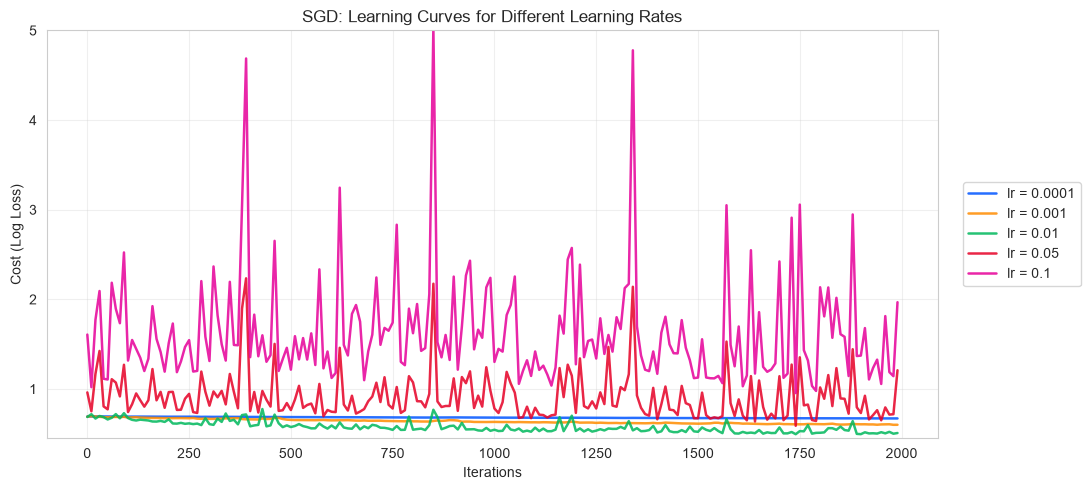

In [16]:
# 2. SGD
plt.figure(figsize=(11, 5))
for color, (lr, res) in zip(palette, all_lr_results["SGD"].items()):
    iters = np.arange(len(res["costs"])) * 10
    plt.plot(iters, res["costs"], color=color, linewidth=1.8, alpha=0.85, label=f"lr = {lr}")
plt.title("SGD: Learning Curves for Different Learning Rates")
plt.xlabel("Iterations")
plt.ylabel("Cost (Log Loss)")
plt.ylim(0.45, 5.0)
plt.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

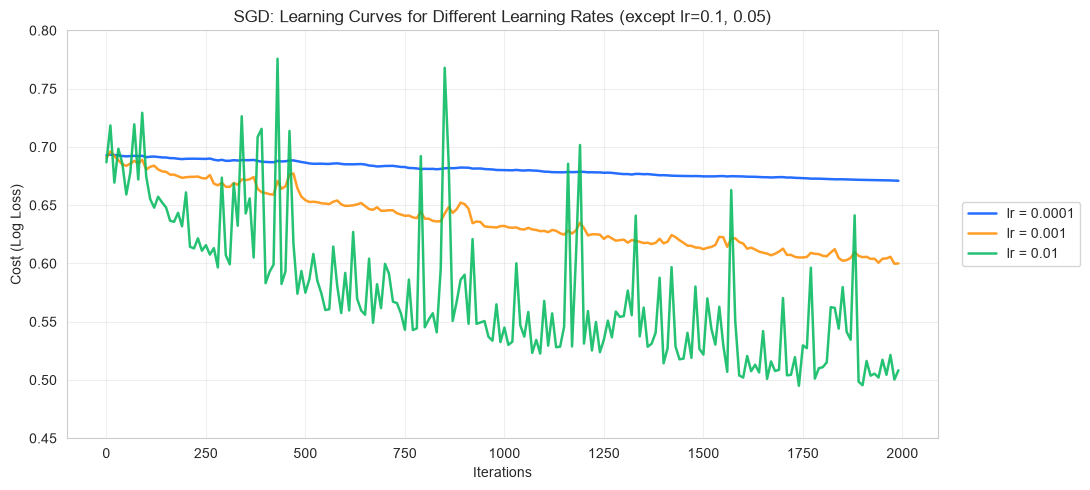

In [19]:
plt.figure(figsize=(11, 5))
for color, (lr, res) in zip(palette, all_lr_results["SGD"].items()):
    if lr == 0.1 or lr == 0.05:
        continue
    iters = np.arange(len(res["costs"])) * 10
    plt.plot(iters, res["costs"], color=color, linewidth=1.8, alpha=0.85, label=f"lr = {lr}")
plt.title("SGD: Learning Curves for Different Learning Rates (except lr=0.1, 0.05)")
plt.xlabel("Iterations")
plt.ylabel("Cost (Log Loss)")
plt.ylim(0.45, 0.8)
plt.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

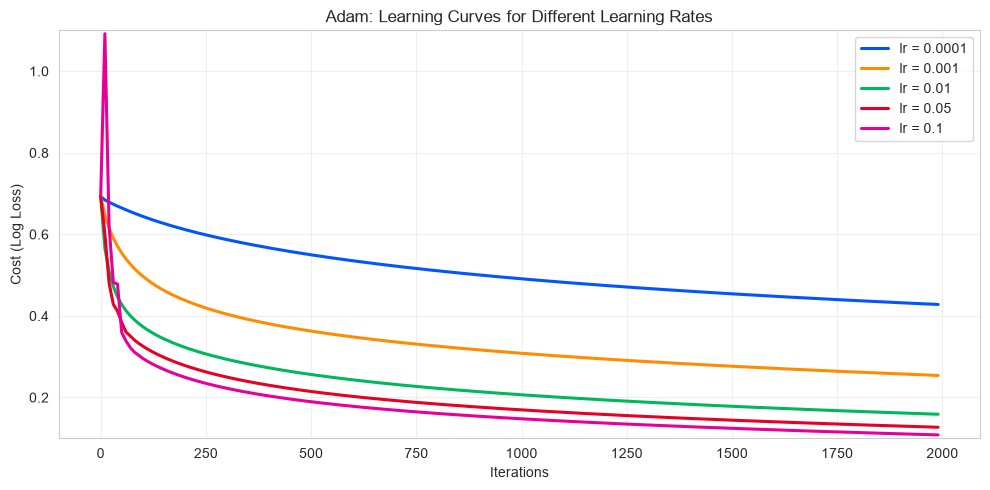

In [18]:
# 3. Adam
plt.figure(figsize=(10, 5))
for color, (lr, res) in zip(palette, all_lr_results["Adam"].items()):
    iters = np.arange(len(res["costs"])) * 10
    plt.plot(iters, res["costs"], color=color, linewidth=2.2, label=f"lr = {lr}")
plt.title("Adam: Learning Curves for Different Learning Rates")
plt.xlabel("Iterations")
plt.ylabel("Cost (Log Loss)")
plt.ylim(0.1, 1.1)
plt.legend(loc="upper right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Conclusions

Classic Gradient Descent produces smooth, monotonically decreasing loss curves because each update uses the exact gradient over the entire training set. Stochastic Gradient Descent runs much faster per iteration, but updating weights on a single random sample introduces strong noise into the loss trajectory and requires more iterations to reach comparable accuracy. Adam converges significantly faster than GD and SGD at the start of training due to momentum and adaptive per-parameter learning rates, achieving the lowest training loss, though without regularization it tends to overfit on a high-dimensional dataset with 1776 descriptors.

The choice of learning rate strongly affects both convergence speed and generalization. Very small values (`0.0001` and `0.001`) make gradient descent too slow, leaving GD and SGD underfitted after 2000 iterations, whereas Adam already reaches good accuracy even at `0.001`. Moderate step sizes (`0.01` to `0.05`) provide the best balance for GD and SGD, while larger values (`0.1`) work well for full-batch GD but cause strong oscillations in SGD and faster overfitting in Adam. Additionally, at larger learning rates (`0.05` and `0.1`), Adam shows a sharp initial spike in the loss curve because bias correction on the first step normalizes the update to roughly $\pm \text{lr}$ across all 1776 weights simultaneously, causing a temporary overshoot before the adaptive second-moment estimates stabilize the trajectory.
